In [57]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Task 1 – Data Loading and Initial Inspection

In [58]:
df = pd.read_csv('Clean_Dataset.csv')

In [59]:
df.head()

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [60]:
df.tail()

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
300148,300148,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,69265
300149,300149,Vistara,UK-826,Chennai,Afternoon,one,Night,Hyderabad,Business,10.42,49,77105
300150,300150,Vistara,UK-832,Chennai,Early_Morning,one,Night,Hyderabad,Business,13.83,49,79099
300151,300151,Vistara,UK-828,Chennai,Early_Morning,one,Evening,Hyderabad,Business,10.00,49,81585
300152,300152,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,81585


In [61]:
df.shape

(300153, 12)

In [62]:
df.columns

Index(['Unnamed: 0', 'airline', 'flight', 'source_city', 'departure_time',
       'stops', 'arrival_time', 'destination_city', 'class', 'duration',
       'days_left', 'price'],
      dtype='str')

In [63]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        300153 non-null  int64  
 1   airline           300153 non-null  str    
 2   flight            300153 non-null  str    
 3   source_city       300153 non-null  str    
 4   departure_time    300153 non-null  str    
 5   stops             300153 non-null  str    
 6   arrival_time      300153 non-null  str    
 7   destination_city  300153 non-null  str    
 8   class             300153 non-null  str    
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), str(8)
memory usage: 27.5 MB


In [64]:
df.describe()

,Unnamed: 0,duration,days_left,price
count,300153.000000,300153.000000,300153.000000,300153.000000
mean,150076.000000,12.221021,26.004751,20889.660523
std,86646.852011,7.191997,13.561004,22697.767366
min,0.000000,0.830000,1.000000,1105.000000
25%,75038.000000,6.830000,15.000000,4783.000000
50%,150076.000000,11.250000,26.000000,7425.000000
75%,225114.000000,16.170000,38.000000,42521.000000
max,300152.000000,49.830000,49.000000,123071.000000


In [65]:
df.describe(include='object')

C:\Users\Nithesh N Acharya\AppData\Local\Temp\ipykernel_45392\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class
count,300153,300153,300153,300153,300153,300153,300153,300153
unique,6,1561,6,6,3,6,6,2
top,Vistara,UK-706,Delhi,Morning,one,Night,Mumbai,Economy
freq,127859,3235,61343,71146,250863,91538,59097,206666


In [66]:
for col in ['airline', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class']:
    print(col, df[col].unique())
    print()

airline <StringArray>
['SpiceJet', 'AirAsia', 'Vistara', 'GO_FIRST', 'Indigo', 'Air_India']
Length: 6, dtype: str

source_city <StringArray>
['Delhi', 'Mumbai', 'Bangalore', 'Kolkata', 'Hyderabad', 'Chennai']
Length: 6, dtype: str

departure_time <StringArray>
['Evening', 'Early_Morning', 'Morning', 'Afternoon', 'Night', 'Late_Night']
Length: 6, dtype: str

stops <StringArray>
['zero', 'one', 'two_or_more']
Length: 3, dtype: str

arrival_time <StringArray>
['Night', 'Morning', 'Early_Morning', 'Afternoon', 'Evening', 'Late_Night']
Length: 6, dtype: str

destination_city <StringArray>
['Mumbai', 'Bangalore', 'Kolkata', 'Hyderabad', 'Chennai', 'Delhi']
Length: 6, dtype: str

class <StringArray>
['Economy', 'Business']
Length: 2, dtype: str



In [67]:
df['flight'].nunique()

1561

# Task 2 – Data Quality Assessment

### Index column

In [68]:
df = df.drop('Unnamed: 0', axis=1)

### Missing values

In [69]:
df.isnull().sum()

airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
class               0
duration            0
days_left           0
price               0
dtype: int64

### Duplicate records

In [70]:
df.duplicated().sum()

np.int64(0)

In [71]:
rows_before = len(df)
df = df.drop_duplicates()
rows_after = len(df)
print(rows_before, rows_after)

300153 300153


### Inconsistent labels and wrong data types

In [72]:
df['flight'].apply(lambda x: type(x).__name__).value_counts()

flight
str    300153
Name: count, dtype: int64

In [73]:
df[df['flight'].apply(lambda x: isinstance(x, float))][['airline', 'flight']].head()

,airline,flight


In [74]:
df = df.drop('flight', axis=1)

In [75]:
for col in ['airline', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class']:
    print(df[col].value_counts())
    print()

airline
Vistara      127859
Air_India     80892
Indigo        43120
GO_FIRST      23173
AirAsia       16098
SpiceJet       9011
Name: count, dtype: int64

source_city
Delhi        61343
Mumbai       60896
Bangalore    52061
Kolkata      46347
Hyderabad    40806
Chennai      38700
Name: count, dtype: int64

departure_time
Morning          71146
Early_Morning    66790
Evening          65102
Night            48015
Afternoon        47794
Late_Night        1306
Name: count, dtype: int64

stops
one            250863
zero            36004
two_or_more     13286
Name: count, dtype: int64

arrival_time
Night            91538
Evening          78323
Morning          62735
Afternoon        38139
Early_Morning    15417
Late_Night       14001
Name: count, dtype: int64

destination_city
Mumbai       59097
Delhi        57360
Bangalore    51068
Kolkata      49534
Hyderabad    42726
Chennai      40368
Name: count, dtype: int64

class
Economy     206666
Business     93487
Name: count, dtype: int64



### Columns with only one value

In [76]:
df.nunique()

airline                 6
source_city             6
departure_time          6
stops                   3
arrival_time            6
destination_city        6
class                   2
duration              476
days_left              49
price               12157
dtype: int64

In [77]:
constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print(constant_cols)
df = df.drop(constant_cols, axis=1)

[]


### Outliers in Price

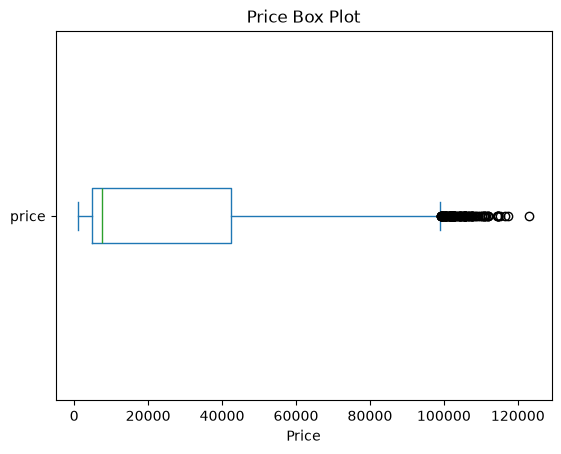

In [78]:
df['price'].plot(kind='box', vert=False)
plt.title('Price Box Plot')
plt.xlabel('Price')
plt.show()

In [79]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1
outliers = df[(df['price'] < Q1 - 1.5 * IQR) | (df['price'] > Q3 + 1.5 * IQR)]
print(len(outliers))
print(outliers['airline'].value_counts())
print(outliers['stops'].value_counts())

123
airline
Vistara    123
Name: count, dtype: int64
stops
one            95
two_or_more    28
Name: count, dtype: int64


# Task 3 – Exploratory Data Analysis

### Price distribution

In [80]:
df['price'].describe()

count    300153.000000
mean      20889.660523
std       22697.767366
min        1105.000000
25%        4783.000000
50%        7425.000000
75%       42521.000000
max      123071.000000
Name: price, dtype: float64

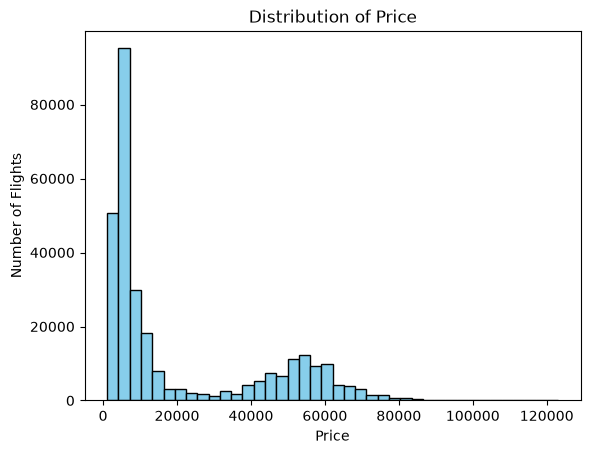

In [81]:
df['price'].plot(kind='hist', bins=40, color='skyblue', edgecolor='black')
plt.title('Distribution of Price')
plt.xlabel('Price')
plt.ylabel('Number of Flights')
plt.show()

### Airline

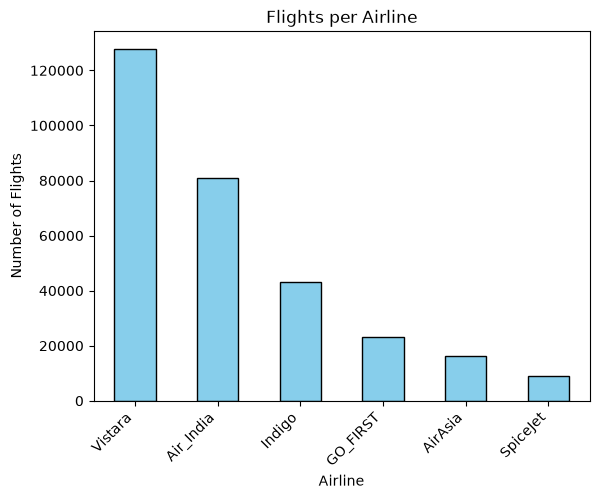

In [82]:
df['airline'].value_counts().plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Flights per Airline')
plt.xlabel('Airline')
plt.ylabel('Number of Flights')
plt.xticks(rotation=45, ha='right')
plt.show()

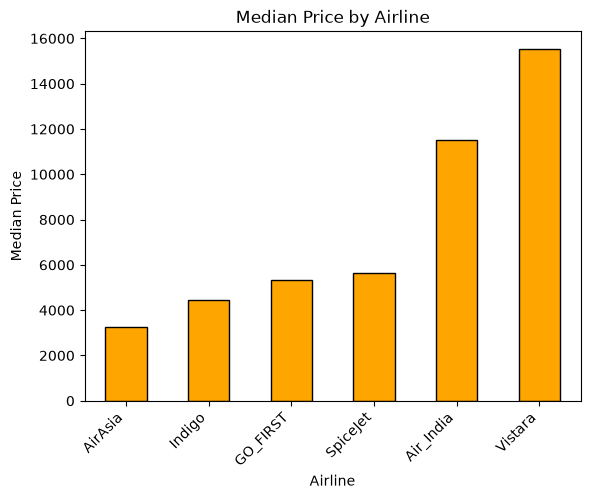

In [83]:
df.groupby('airline')['price'].median().sort_values().plot(kind='bar', color='orange', edgecolor='black')
plt.title('Median Price by Airline')
plt.xlabel('Airline')
plt.ylabel('Median Price')
plt.xticks(rotation=45, ha='right')
plt.show()

### Destination

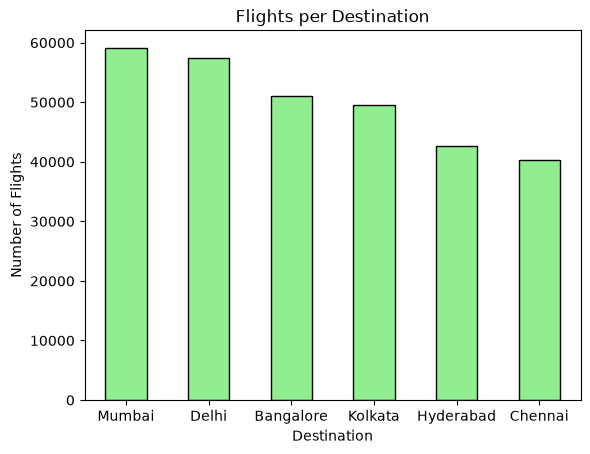

In [84]:
df['destination_city'].value_counts().plot(kind='bar', color='lightgreen', edgecolor='black')
plt.title('Flights per Destination')
plt.xlabel('Destination')
plt.ylabel('Number of Flights')
plt.xticks(rotation=0)
plt.show()

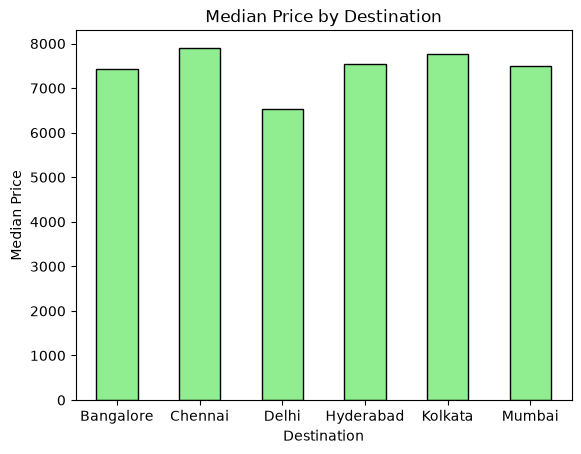

In [85]:
df.groupby('destination_city')['price'].median().plot(kind='bar', color='lightgreen', edgecolor='black')
plt.title('Median Price by Destination')
plt.xlabel('Destination')
plt.ylabel('Median Price')
plt.xticks(rotation=0)
plt.show()

### Departure and arrival time of day

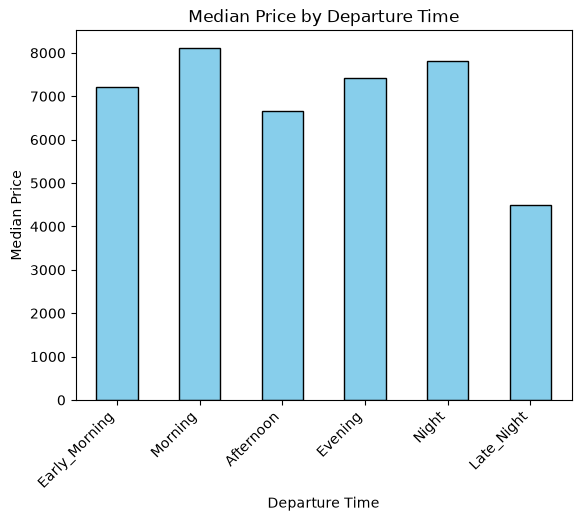

In [86]:
time_order = ['Early_Morning', 'Morning', 'Afternoon', 'Evening', 'Night', 'Late_Night']
df.groupby('departure_time')['price'].median().reindex(time_order).plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Median Price by Departure Time')
plt.xlabel('Departure Time')
plt.ylabel('Median Price')
plt.xticks(rotation=45, ha='right')
plt.show()

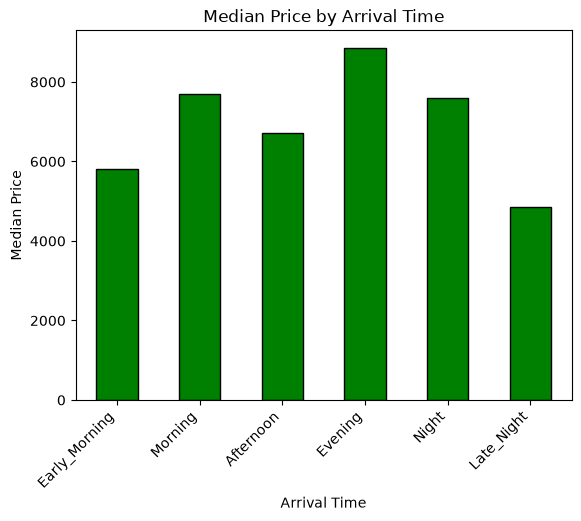

In [87]:
df.groupby('arrival_time')['price'].median().reindex(time_order).plot(kind='bar', color='green', edgecolor='black')
plt.title('Median Price by Arrival Time')
plt.xlabel('Arrival Time')
plt.ylabel('Median Price')
plt.xticks(rotation=45, ha='right')
plt.show()

### Days left before departure

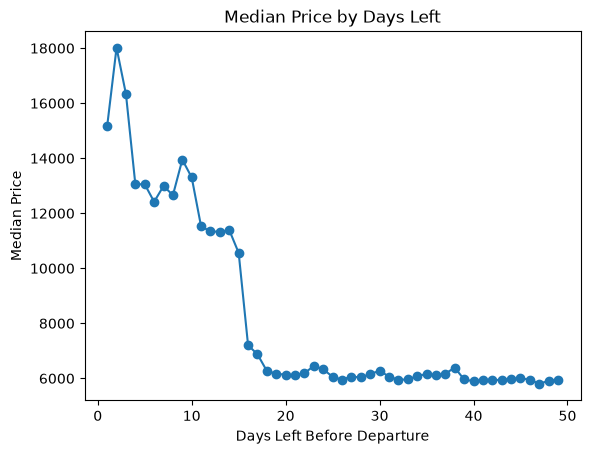

In [88]:
df.groupby('days_left')['price'].median().plot(kind='line', marker='o')
plt.title('Median Price by Days Left')
plt.xlabel('Days Left Before Departure')
plt.ylabel('Median Price')
plt.show()

# Task 4 – Date and Time Feature Engineering

This dataset has **no raw date or clock-time text** (there is no `Date_of_Journey`, `Dep_Time` or `Arrival_Time` like `24/03/2019` or `22:20`), so splitting into day/month/year or hour/minute is not possible. The date and time information is stored in three columns, which are checked below.

### days_left (replaces the journey date)

In [89]:
df['days_left'].describe()

count    300153.000000
mean         26.004751
std          13.561004
min           1.000000
25%          15.000000
50%          26.000000
75%          38.000000
max          49.000000
Name: days_left, dtype: float64

In [90]:
print((df['days_left'] <= 0).sum())
print(df['days_left'].isnull().sum())

0
0


### departure_time and arrival_time (replace Dep_Time and Arrival_Time)

In [91]:
print(df['departure_time'].isin(time_order).all())
print(df['arrival_time'].isin(time_order).all())

True
True


# Task 5 – Stops and Duration Transformation

### stops

In [92]:
df['stops'].value_counts(dropna=False)

stops
one            250863
zero            36004
two_or_more     13286
Name: count, dtype: int64

In [93]:
df['stops'] = df['stops'].map({'zero': 0, 'one': 1, 'two_or_more': 2})
df['stops'].value_counts(dropna=False)

stops
1    250863
0     36004
2     13286
Name: count, dtype: int64

### duration

In [94]:
df['duration'].describe()

count    300153.000000
mean         12.221021
std           7.191997
min           0.830000
25%           6.830000
50%          11.250000
75%          16.170000
max          49.830000
Name: duration, dtype: float64

`duration` is already numeric but in **hours** (for example `2.17` = about 2 h 10 min). It is converted to total minutes so it matches the assignment format.

In [95]:
df['duration_minutes'] = (df['duration'] * 60).round().astype(int)
df[['duration', 'duration_minutes']].head()

,duration,duration_minutes
0,2.17,130
1,2.33,140
2,2.17,130
3,2.25,135
4,2.33,140


In [96]:
print((df['duration_minutes'] <= 0).sum())
df['duration_minutes'].describe()

0


count    300153.000000
mean        733.259055
std         431.518381
min          50.000000
25%         410.000000
50%         675.000000
75%         970.000000
max        2990.000000
Name: duration_minutes, dtype: float64

In [97]:
df = df.drop('duration', axis=1)

The original `duration` column was dropped because `duration_minutes` holds the same information in minutes.

# Task 3 (continued) – Stops, Duration and Correlation vs Price

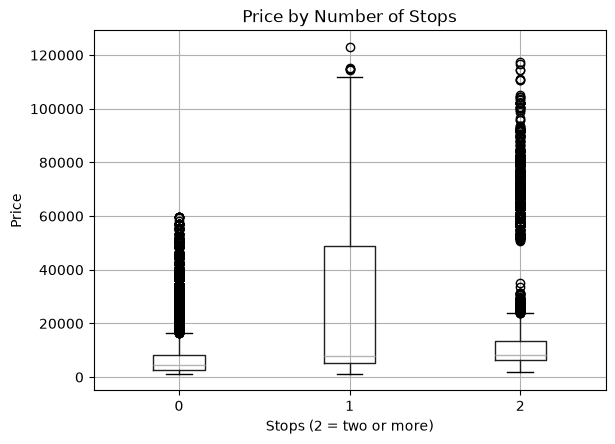

In [98]:
df.boxplot(column='price', by='stops')
plt.title('Price by Number of Stops')
plt.suptitle('')
plt.xlabel('Stops (2 = two or more)')
plt.ylabel('Price')
plt.show()

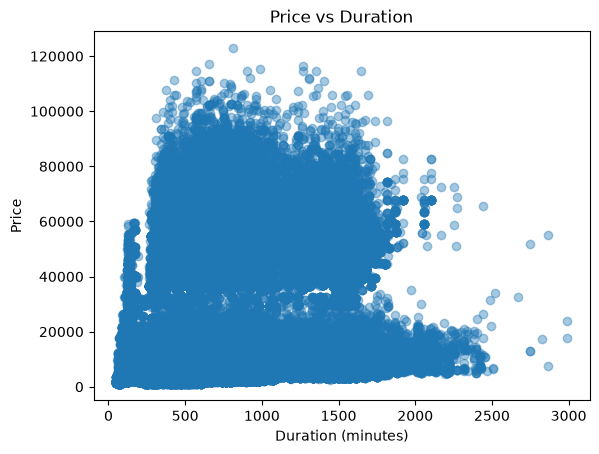

In [99]:
plt.scatter(df['duration_minutes'], df['price'], alpha=0.4)
plt.title('Price vs Duration')
plt.xlabel('Duration (minutes)')
plt.ylabel('Price')
plt.show()

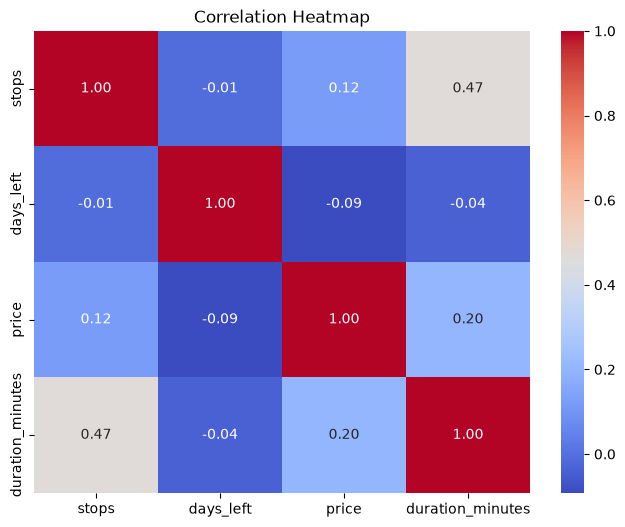

In [100]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

### Insights

In [101]:
print('1. Mean price', round(df['price'].mean()), 'is higher than median', round(df['price'].median()), '-> price is right-skewed.')
print('2. Airline with most flights:', df['airline'].value_counts().index[0])
print('3. Airline with highest median price:', df.groupby('airline')['price'].median().idxmax())
print('4. Airline with lowest median price:', df.groupby('airline')['price'].median().idxmin())
print('5. Median price by stops:')
print(df.groupby('stops')['price'].median())
print('6. Correlation of price with days_left:', round(df['price'].corr(df['days_left']), 2))
print('7. Correlation of price with duration:', round(df['price'].corr(df['duration_minutes']), 2))
print('8. Median price by destination:')
print(df.groupby('destination_city')['price'].median())

1. Mean price 20890 is higher than median 7425 -> price is right-skewed.
2. Airline with most flights: Vistara
3. Airline with highest median price: Vistara
4. Airline with lowest median price: AirAsia
5. Median price by stops:
stops
0    4499.0
1    7959.0
2    8307.0
Name: price, dtype: float64
6. Correlation of price with days_left: -0.09
7. Correlation of price with duration: 0.2
8. Median price by destination:
destination_city
Bangalore    7425.0
Chennai      7900.0
Delhi        6521.0
Hyderabad    7548.0
Kolkata      7767.0
Mumbai       7496.0
Name: price, dtype: float64


**Write your own insights here (at least five), for example:**
- Price is right-skewed because a few expensive fares pull the mean above the median.
- Airline matters: compare the airlines with the highest and lowest median prices.
- More stops and longer duration go with higher prices, and these two are related.
- Booking close to departure (small `days_left`) costs much more than booking early.
- Destination and time of day show smaller differences than airline and days_left.

# Task 6 – Categorical Feature Encoding

In [102]:
df.select_dtypes(include=['object', 'string']).columns

Index(['airline', 'source_city', 'departure_time', 'arrival_time',
       'destination_city', 'class'],
      dtype='str')

In [103]:
cat_cols = df.select_dtypes(include=['object', 'string']).columns.tolist()
df = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)
df.columns

Index(['stops', 'days_left', 'price', 'duration_minutes', 'airline_Air_India',
       'airline_GO_FIRST', 'airline_Indigo', 'airline_SpiceJet',
       'airline_Vistara', 'source_city_Chennai', 'source_city_Delhi',
       'source_city_Hyderabad', 'source_city_Kolkata', 'source_city_Mumbai',
       'departure_time_Early_Morning', 'departure_time_Evening',
       'departure_time_Late_Night', 'departure_time_Morning',
       'departure_time_Night', 'arrival_time_Early_Morning',
       'arrival_time_Evening', 'arrival_time_Late_Night',
       'arrival_time_Morning', 'arrival_time_Night',
       'destination_city_Chennai', 'destination_city_Delhi',
       'destination_city_Hyderabad', 'destination_city_Kolkata',
       'destination_city_Mumbai', 'class_Economy'],
      dtype='str')

In [104]:
df.sample(5)

,stops,days_left,price,duration_minutes,airline_Air_India,airline_GO_FIRST,airline_Indigo,airline_SpiceJet,airline_Vistara,source_city_Chennai,...,arrival_time_Evening,arrival_time_Late_Night,arrival_time_Morning,arrival_time_Night,destination_city_Chennai,destination_city_Delhi,destination_city_Hyderabad,destination_city_Kolkata,destination_city_Mumbai,class_Economy
294762,1,27,60260,855,1,0,0,0,0,1,...,0,1,0,0,0,0,0,0,0,0
278370,0,20,17794,95,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,1,0
45745,1,16,6122,305,0,0,0,0,1,0,...,0,0,0,0,0,1,0,0,0,1
76711,1,45,4779,985,0,0,0,0,1,0,...,0,0,0,1,0,0,1,0,0,1
202414,1,47,4784,555,1,0,0,0,0,1,...,1,0,0,0,0,0,0,1,0,1


# Task 7 – Final Dataset Validation

In [105]:
df.head()

,stops,days_left,price,duration_minutes,airline_Air_India,airline_GO_FIRST,airline_Indigo,airline_SpiceJet,airline_Vistara,source_city_Chennai,...,arrival_time_Evening,arrival_time_Late_Night,arrival_time_Morning,arrival_time_Night,destination_city_Chennai,destination_city_Delhi,destination_city_Hyderabad,destination_city_Kolkata,destination_city_Mumbai,class_Economy
0,0,1,5953,130,0,0,0,1,0,0,...,0,0,0,1,0,0,0,0,1,1
1,0,1,5953,140,0,0,0,1,0,0,...,0,0,1,0,0,0,0,0,1,1
2,0,1,5956,130,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,1
3,0,1,5955,135,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,1,1
4,0,1,5955,140,0,0,0,0,1,0,...,0,0,1,0,0,0,0,0,1,1


In [106]:
df.shape

(300153, 30)

In [107]:
df.columns

Index(['stops', 'days_left', 'price', 'duration_minutes', 'airline_Air_India',
       'airline_GO_FIRST', 'airline_Indigo', 'airline_SpiceJet',
       'airline_Vistara', 'source_city_Chennai', 'source_city_Delhi',
       'source_city_Hyderabad', 'source_city_Kolkata', 'source_city_Mumbai',
       'departure_time_Early_Morning', 'departure_time_Evening',
       'departure_time_Late_Night', 'departure_time_Morning',
       'departure_time_Night', 'arrival_time_Early_Morning',
       'arrival_time_Evening', 'arrival_time_Late_Night',
       'arrival_time_Morning', 'arrival_time_Night',
       'destination_city_Chennai', 'destination_city_Delhi',
       'destination_city_Hyderabad', 'destination_city_Kolkata',
       'destination_city_Mumbai', 'class_Economy'],
      dtype='str')

In [108]:
df.dtypes

stops                           int64
days_left                       int64
price                           int64
duration_minutes                int64
airline_Air_India               int64
airline_GO_FIRST                int64
airline_Indigo                  int64
airline_SpiceJet                int64
airline_Vistara                 int64
source_city_Chennai             int64
source_city_Delhi               int64
source_city_Hyderabad           int64
source_city_Kolkata             int64
source_city_Mumbai              int64
departure_time_Early_Morning    int64
departure_time_Evening          int64
departure_time_Late_Night       int64
departure_time_Morning          int64
departure_time_Night            int64
arrival_time_Early_Morning      int64
arrival_time_Evening            int64
arrival_time_Late_Night         int64
arrival_time_Morning            int64
arrival_time_Night              int64
destination_city_Chennai        int64
destination_city_Delhi          int64
destination_

In [109]:
df.isnull().sum().sum()

np.int64(0)

In [110]:
df.select_dtypes(include=['object', 'string']).columns

Index([], dtype='str')

In [111]:
print('Rows after removing duplicates:', rows_after)
print('Rows in final dataset:', len(df))

Rows after removing duplicates: 300153
Rows in final dataset: 300153


In [112]:
y = df['price']
X = df.drop('price', axis=1)
print('Target:', y.name)
print('Input features:', X.shape[1])

Target: price
Input features: 29


In [115]:
df.to_csv('flight_price_cleaned.csv', index=False)

# Conclusion
- Dropped the old index column, found no missing values or duplicates, and kept the price outliers because they look like genuine fares.
- Found that Excel corrupted the `flight` codes (many became `0.0`), so that column was dropped; the constant columns `source_city` and `class` were also dropped in this file.
- The dataset has no raw date or clock times, so Task 4 validated `days_left`, `departure_time` and `arrival_time` instead of splitting them.
- Converted `stops` to numbers (0, 1, 2 = two or more) and `duration` from hours to minutes.
- Airline, days left before departure, stops and duration are the clearest drivers of price.
- One-hot encoded the remaining categorical columns, kept `price` as the target, confirmed no missing values or text columns remain, and saved the result to `flight_price_cleaned.csv`.